# 02 — Clustering experiments: hierarchical vs K-means on the Phase 1 baseline

Implements the Phase 2 plan in `reports/phase_1_summary.md`:

1. construct the claim-level feature matrix;
2. transform skewed variables (`log1p`) and standardise;
3. hierarchical clustering (Ward) and the dendrogram;
4. compare candidate numbers of clusters with internal diagnostics;
5. cross-check with K-means;
6. stability (bootstrap);
7. sensitivity to correlated features and to extreme claims;
8. actuarial interpretation of the groups.

**Scope reminder.** The baseline features (ultimate claim size, final settlement delay, final number of payments, notification delay) are known only after settlement. This is an **ex-post** segmentation of completed claim profiles. The valuation-date version is in notebook 03.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from src.data.splice import load_splice
from src.features.clustering import internal_diagnostics, bootstrap_stability
pd.set_option("display.width", 200)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)

claims = load_splice("complexity_5").claims
F = ["claim_size", "notidel", "setldel", "no_payment"]
def matrix(df, cols):
    return StandardScaler().fit_transform(np.log1p(df[cols]))
X = matrix(claims, F)
X.shape

(3663, 4)

## 1. Ward hierarchical clustering — dendrogram

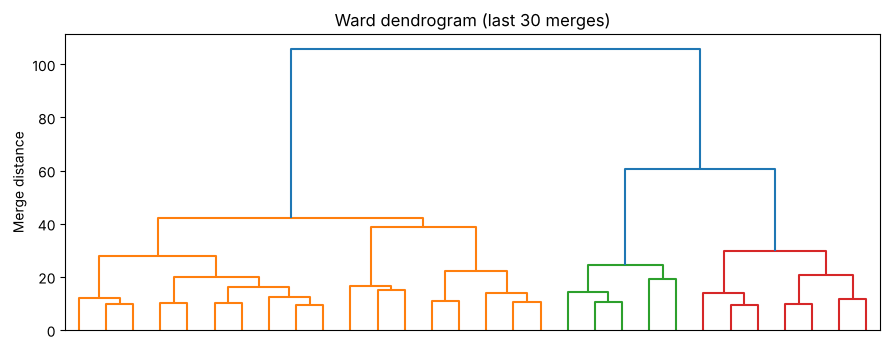

1→2    105.9
2→3     60.7
3→4     42.0
4→5     38.6
5→6     29.7
6→7     27.7
7→8     24.3
8→9     22.2
Name: merge height (top), dtype: float64

In [2]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(9, 3.6))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=Z[-2, 2], ax=ax)
ax.set_title("Ward dendrogram (last 30 merges)"); ax.set_ylabel("Merge distance")
fig.tight_layout(); fig.savefig(FIG / "phase2_dendrogram.png", dpi=150); plt.show()
heights = Z[::-1, 2][:8]
pd.Series(heights, index=[f"{k}→{k+1}" for k in range(1, 9)], name="merge height (top)").round(1)

The largest jump in merge height is between one and two clusters; the next jumps are much smaller and similar to each other, so the dendrogram supports **two clear groups**, with finer splits being a matter of choice rather than structure.

## 2. Choosing the number of clusters — internal diagnostics

In [3]:
rows = []
for k in range(2, 9):
    lab_km = KMeans(k, n_init=20, random_state=42).fit_predict(X)
    lab_w = fcluster(Z, k, criterion="maxclust") - 1
    for name, lab in (("K-means", lab_km), ("Ward", lab_w)):
        rows.append({"k": k, "method": name, **internal_diagnostics(X, lab)})
    rows.append({"k": k, "method": "agreement", "ARI K-means vs Ward": adjusted_rand_score(lab_km, lab_w)})
diag = pd.DataFrame(rows)
diag.to_csv(TAB / "phase2_diagnostics.csv", index=False)
diag.pivot(index="k", columns="method", values=["silhouette", "calinski_harabasz", "davies_bouldin", "smallest_cluster"]).round(3)

silhouette                  calinski_harabasz                     davies_bouldin                  smallest_cluster                  
method    K-means   Ward agreement           K-means      Ward agreement        K-means   Ward agreement          K-means    Ward agreement
k                                                                                                                                          
2           0.398  0.337       NaN          2563.499  2271.714       NaN          1.000  1.172       NaN            932.0  1338.0       NaN
3           0.265  0.261       NaN          2128.099  1894.761       NaN          1.285  1.199       NaN            658.0   589.0       NaN
4           0.252  0.195       NaN          1910.638  1608.874       NaN          1.193  1.546       NaN            581.0   589.0       NaN
5           0.251  0.202       NaN          1747.564  1489.697       NaN          1.251  1.349       NaN            523.0   357.0       NaN
6           0.239  0.189       NaN          1659.363  1357.017       NaN          1.174  1.377       NaN            449.0   241.0       NaN
7           0.227  0.162       NaN          1553.031  1271.133       NaN          1.231  1.403       NaN            268.0   241.0       NaN
8           0.216  0.154       NaN          1450.321  1196.012       NaN          1.278  1.454       NaN            248.0   241.0       NaN

In [4]:
ari = diag[diag.method == "agreement"].set_index("k")["ARI K-means vs Ward"].round(3); ari

k
2    0.585
3    0.469
4    0.334
5    0.334
6    0.413
7    0.496
8    0.433
Name: ARI K-means vs Ward, dtype: float64

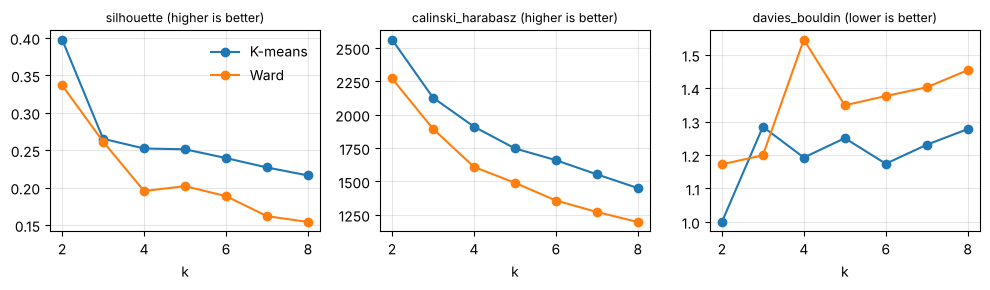

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, m, better in zip(axes, ["silhouette", "calinski_harabasz", "davies_bouldin"], ["higher", "higher", "lower"]):
    for name in ("K-means", "Ward"):
        d = diag[diag.method == name]; ax.plot(d.k, d[m], marker="o", label=name)
    ax.set_title(f"{m} ({better} is better)", fontsize=9); ax.set_xlabel("k"); ax.grid(alpha=.3)
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "phase2_diagnostics.png", dpi=150); plt.show()

All three diagnostics prefer **k = 2** for both methods, and K-means scores better than Ward at every k. Beyond k = 2 the diagnostics flatten: there is no second natural number of groups. Agreement between the methods is moderate (ARI about 0.6 at k = 2, 0.3–0.5 above), so beyond the main split the partition depends on the algorithm.

## 3. Stability — bootstrap

In [6]:
stab = []
for k in (2, 3, 4, 5):
    for m in ("kmeans", "ward"):
        a = bootstrap_stability(X, k, m, n_boot=20)
        stab.append({"k": k, "method": m, "mean ARI": a.mean(), "5th pct": np.quantile(a, .05)})
stab = pd.DataFrame(stab); stab.to_csv(TAB / "phase2_stability.csv", index=False)
stab.pivot(index="k", columns="method", values=["mean ARI", "5th pct"]).round(3)

mean ARI        5th pct       
method   kmeans   ward  kmeans   ward
k                                    
2         0.964  0.490   0.929  0.204
3         0.941  0.510   0.867  0.193
4         0.799  0.406   0.556  0.285
5         0.788  0.411   0.423  0.280

A mean ARI above about 0.75–0.8 is usually read as a stable partition (Hennig, 2007, uses a similar Jaccard-based threshold).

## 4. Sensitivity to correlated features and extreme claims

Claim size, settlement delay and number of payments are strongly correlated (Spearman 0.54–0.68), so 'complexity' may be counted three times. We refit K-means on alternative feature sets and compare each partition with the baseline (all four features).

In [7]:
from sklearn.decomposition import PCA
base = {k: KMeans(k, n_init=20, random_state=42).fit_predict(X) for k in (2, 3, 4)}
L = np.log1p(claims[F]); S = (L - L.mean()) / L.std()
complexity = PCA(1).fit_transform(S[["claim_size", "setldel", "no_payment"]])[:, 0]
variants = {
    "all four (baseline)": X,
    "drop no_payment": matrix(claims, ["claim_size", "notidel", "setldel"]),
    "drop setldel": matrix(claims, ["claim_size", "notidel", "no_payment"]),
    "claim_size + notidel": matrix(claims, ["claim_size", "notidel"]),
    "complexity index + notidel": StandardScaler().fit_transform(np.c_[complexity, S["notidel"]]),
    "PCA-whitened (decorrelated)": PCA(whiten=True).fit_transform(X),
}
rows = []
for name, Xv in variants.items():
    for k in (2, 3, 4):
        lab = KMeans(k, n_init=20, random_state=42).fit_predict(Xv)
        rows.append({"features": name, "k": k, "ARI vs baseline": adjusted_rand_score(base[k], lab),
                     "silhouette": internal_diagnostics(Xv, lab)["silhouette"]})
# extreme claims: drop the largest 1% and compare on the remaining claims
keep = (claims["claim_size"] < claims["claim_size"].quantile(.99)).values
for k in (2, 3, 4):
    lab = KMeans(k, n_init=20, random_state=42).fit_predict(matrix(claims[keep], F))
    rows.append({"features": "drop largest 1% of claims", "k": k, "ARI vs baseline": adjusted_rand_score(base[k][keep], lab), "silhouette": np.nan})
sens = pd.DataFrame(rows); sens.to_csv(TAB / "phase2_sensitivity.csv", index=False)
sens.pivot(index="features", columns="k", values="ARI vs baseline").round(3)

k,2,3,4
features,,,
PCA-whitened (decorrelated),0.338,0.255,0.359
all four (baseline),1.000,1.000,1.000
claim_size + notidel,0.313,0.578,0.410
complexity index + notidel,0.428,0.613,0.405
drop largest 1% of claims,0.991,0.971,0.987
drop no_payment,0.635,0.600,0.646
drop setldel,0.737,0.683,0.523


## 5. Interpretation of the groups

In [8]:
def profile(lab):
    g = claims.groupby(lab)
    p = g[F].median().rename(columns=lambda c: f"median {c}")
    p.insert(0, "n claims", g.size()); p["share of total cost %"] = 100 * g["claim_size"].sum() / claims["claim_size"].sum()
    p["share below 20k %"] = 100 * g["claim_size"].apply(lambda s: (s < 20000).mean())
    return p.round(1)
lab2 = pd.Series(base[2], index=claims.index); lab4 = pd.Series(base[4], index=claims.index)
prof = pd.concat({"k=2": profile(lab2), "k=4": profile(lab4)}); prof.to_csv(TAB / "phase2_profiles.csv"); prof

n claims  median claim_size  median notidel  median setldel  median no_payment  share of total cost %  share below 20k %
k=2 0       932             8474.4             2.7             1.5                2.0                    1.9               83.4
    1      2731           125462.9             1.5            10.6                5.0                   98.1                2.1
k=4 0      1002            64200.3             3.3             7.9                4.0                   16.7               10.6
    1       900            51799.8             1.0             5.2                4.0                   13.6               16.8
    2      1180           251263.6             1.2            16.1                7.0                   69.2                0.0
    3       581             4136.7             2.7             1.0                2.0                    0.5               99.1

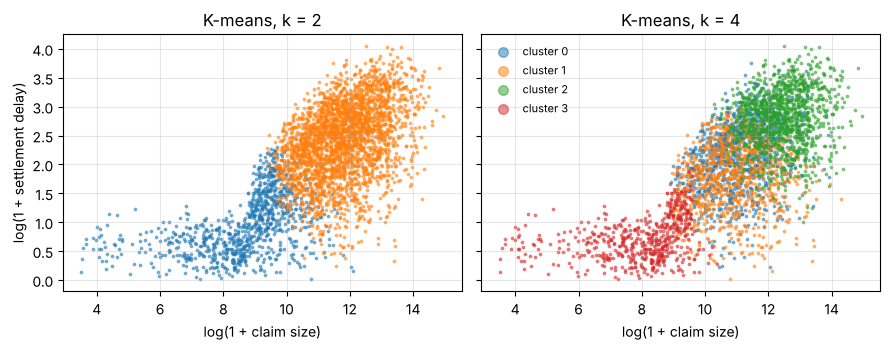

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for a, (k, lab) in zip(ax, ((2, lab2), (4, lab4))):
    for g in sorted(lab.unique()):
        m = lab == g
        a.scatter(np.log1p(claims.loc[m, "claim_size"]), np.log1p(claims.loc[m, "setldel"]), s=3, alpha=.5, label=f"cluster {g}")
    a.set_title(f"K-means, k = {k}"); a.set_xlabel("log(1 + claim size)"); a.grid(alpha=.3)
ax[0].set_ylabel("log(1 + settlement delay)"); ax[1].legend(frameon=False, markerscale=4, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "phase2_clusters_scatter.png", dpi=150); plt.show()

In [10]:
# Do the clusters line up with occurrence period? (secondary diagnostic, Phase 1 §6)
pd.crosstab(pd.cut(claims["occurrence_period"], [0, 10, 20, 30, 40]), lab4, normalize="index").round(3)

col_0,0,1,2,3
occurrence_period,,,,
"(0, 10]",0.288,0.228,0.348,0.136
"(10, 20]",0.260,0.268,0.302,0.169
"(20, 30]",0.258,0.257,0.312,0.173
"(30, 40]",0.288,0.228,0.326,0.157


## 6. Conclusions

1. **One natural split.** The dendrogram, all three internal diagnostics and both algorithms point to **k = 2**. It separates small, quickly settled claims (932 claims; median size 8.5k, settled in 1.5 quarters, 2 payments; 1.9% of total cost; 83% of them below 20k) from all other claims. This is the band of short-delay claims found in Phase 1.
2. **K-means is preferable to Ward here.** It scores better on every diagnostic at every k. It is also much more stable under resampling: bootstrap ARI is 0.96 (k = 2) and 0.94 (k = 3), falling to about 0.8 at k = 4–5. Ward scores only 0.4–0.5 at every k, because its sequence of greedy merges changes with the sample. The two methods agree only moderately (ARI 0.33–0.59).
3. **Beyond k = 2 the partition reflects modelling choices more than structure.**
   - Dropping one of the three correlated 'complexity' variables changes the partition substantially (ARI 0.52–0.74 against the baseline).
   - Decorrelating the features (whitening, or a single complexity index) changes it even more (ARI 0.26–0.61).
   - Finer clusters therefore need an actuarial reason for how much weight complexity should get; the data alone cannot decide.
4. **Robust to extreme claims.** Removing the largest 1% of claims leaves the partition almost unchanged (ARI ≥ 0.97).
5. **Interpretation at k = 4 (K-means).**
   - Very small, fast claims: 581 claims, 0.5% of cost.
   - Large, long and payment-heavy claims: 1,180 claims, 69% of cost, settled in a median of 16 quarters with 7 payments.
   - Two mid-size groups that differ mainly in notification delay (median 3.3 vs 1.0 quarters).

   The mix is stable across occurrence periods.
6. **Recommendation.**
   - Use K-means.
   - Report k = 2 as the structure in the data, and k = 3–4 as an operational segmentation, together with the sensitivity results above.
   - Remember this is ex-post. Notebook 03 tests whether segmentation on valuation-date information helps reserving.